In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## PREPROCESS



In [40]:
df = pd.read_excel(r'E:\Users\raphiel\Desktop\Python Practice\Tugas EVDA 1\Data Posbindu-1.xlsx')

In [41]:
print("Ukuran data awal:", df.shape)

# hapus baris duplikat
print("Jumlah baris duplikat:", df.duplicated().sum())
df = df.drop_duplicates()
print("Ukuran data sekarang:", df.shape)

Ukuran data awal: (323, 22)
Jumlah baris duplikat: 3
Ukuran data sekarang: (320, 22)


In [42]:
# untuk kolom Denyut Nadi yang berisi teks "na" kita jadikan kosong (NaN) dan ubah ke angka
df["Denyut Nadi (bpm)"] = pd.to_numeric(df["Denyut Nadi (bpm)"], errors="coerce")

In [45]:
# cek variasi penulisan nama kota sebelum kita seragamkan
def cek_variasi_kota(df, nama_kolom="Kota"):
    # Menghitung jumlah masing-masing variasi
    variasi_counts = df[nama_kolom].value_counts()
    
    hasil_format = [f"{kota}: {count}" for kota, count in variasi_counts.items()]
    
    # menggabungkan semua list menjadi satu string dengan pemisah koma
    hasil_akhir = ", ".join(hasil_format)
    
    # Pastikan print sejajar dengan baris di atasnya
    print(f"Total variasi penulisan: {len(variasi_counts)}")
    print(f"Dari data dengan kolom '{nama_kolom}' ini terliput: {hasil_akhir}")
    return variasi_counts

hasil_variasi_kota = cek_variasi_kota(df, "Kota")
print(hasil_variasi_kota)

Total variasi penulisan: 18
Dari data dengan kolom 'Kota' ini terliput: Jakarta: 59, Semarang: 43, Bandung: 39, Denpasar: 38, Yogyakarta: 34, Surabaya: 29, Makassar: 27, Medan: 21, Kota Denpasar: 6, SEMARANG: 3, jakarta: 3, MAKASSAR: 3, DKI Jakarta: 3, Yogya: 3, DIY Yogyakarta: 3, Kota Medan: 2, bandung: 2, Kota Bandung: 2
Kota
Jakarta           59
Semarang          43
Bandung           39
Denpasar          38
Yogyakarta        34
Surabaya          29
Makassar          27
Medan             21
Kota Denpasar      6
SEMARANG           3
jakarta            3
MAKASSAR           3
DKI Jakarta        3
Yogya              3
DIY Yogyakarta     3
Kota Medan         2
bandung            2
Kota Bandung       2
Name: count, dtype: int64


In [53]:
# menyeragamkan penulisan nama kota
def seragamkan_kota(data_kota, nama_kolom="Kota"):

    # buat daftar nama kota yang sudah diseragamkan
    daftar_kota = {
        "jakarta": "Jakarta",
        "dki jakarta": "Jakarta",

        "bandung": "Bandung",
        "kota bandung": "Bandung",

        "semarang": "Semarang",

        "denpasar": "Denpasar",
        "kota denpasar": "Denpasar",

        "yogyakarta": "Yogyakarta",
        "yogya": "Yogyakarta",
        "diy yogyakarta": "Yogyakarta",

        "surabaya": "Surabaya",

        "makassar": "Makassar",

        "medan": "Medan",
        "kota medan": "Medan"
    }

    # membersihkan penulisan nama kota
    data_kota[nama_kolom] = data_kota[nama_kolom].astype("string")
    data_kota[nama_kolom] = data_kota[nama_kolom].str.strip()
    data_kota[nama_kolom] = data_kota[nama_kolom].str.lower()

    # mengganti nama kota yang penulisannya berbeda
    data_kota[nama_kolom] = data_kota[nama_kolom].replace(daftar_kota)

    # menyeragamkan huruf kapital
    data_kota[nama_kolom] = data_kota[nama_kolom].str.title()

    # menampilkan hasil penyeragaman
    print("jumlah variasi nama kota setelah diseragamkan:",
          data_kota[nama_kolom].nunique())

    return data_kota

print(df["Kota"].value_counts())


Kota
Jakarta       65
Semarang      46
Denpasar      44
Bandung       43
Yogyakarta    40
Makassar      30
Surabaya      29
Medan         23
Name: count, dtype: Int64


Ukuran data awal: (323, 22)
Jumlah baris duplikat: 3
Ukuran data sekarang: (320, 22)
Variasi sebelum: 18
Variasi sesudah: 8
Kota
Jakarta       65
Semarang      46
Denpasar      44
Bandung       43
Yogyakarta    40
Makassar      30
Surabaya      29
Medan         23
Name: count, dtype: int64
Tanggal Lahir                 6
Tinggi Badan (cm)             6
Berat Badan (kg)              7
Lingkar Perut (cm)            9
Sistol (mmHg)                 5
Diastol (mmHg)                5
Denyut Nadi (bpm)             3
Gula Darah Sewaktu (mg/dL)    6
Kolesterol Total (mg/dL)      6
Asam Urat (mg/dL)             7
dtype: int64
Persen terhadap 320 baris:
Tanggal Lahir                 1.9
Tinggi Badan (cm)             1.9
Berat Badan (kg)              2.2
Lingkar Perut (cm)            2.8
Sistol (mmHg)                 1.6
Diastol (mmHg)                1.6
Denyut Nadi (bpm)             0.9
Gula Darah Sewaktu (mg/dL)    1.9
Kolesterol Total (mg/dL)      1.9
Asam Urat (mg/dL)             2.2
dtype: fl

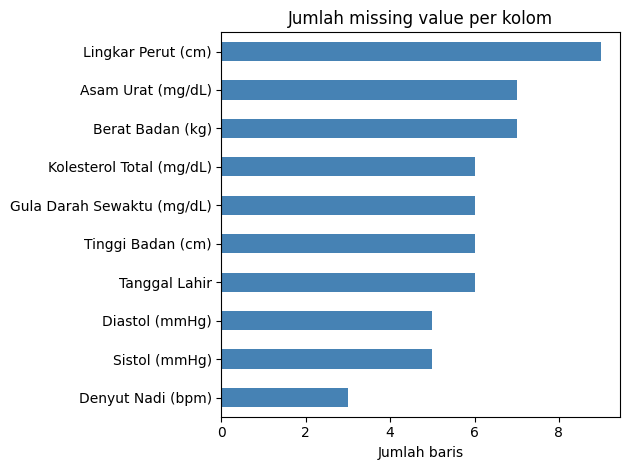

Ukuran data akhir: (320, 31)

Status_Tensi
Status_Tensi
Normal        299
Hipertensi     12
NaN             9

Kat_GDS
Kat_GDS
Normal         224
Pradiabetes     59
Diabetes        31
NaN              6

Kat_Kolesterol
Kat_Kolesterol
Normal        229
Borderline     83
NaN             6
Tinggi          2

Status_AsamUrat
Status_AsamUrat
Normal           266
Hiperurikemia     47
NaN                7

Obesitas_Sentral
Obesitas_Sentral
Tidak    210
Ya       101
NaN        9

Kelompok_IMT
Kelompok_IMT
Obesitas      137
Normal         87
Overweight     53
Kurus          30
NaN            13

Kelompok_Usia
Kelompok_Usia
50-59    79
40-49    79
60+      68
30-39    54
<30      34
NaN       6

Tersimpan: Data_Posbindu_bersih.xlsx


In [ ]:

# %% 5. Nilai yang tidak masuk akal -> dikosongkan
# 8888 kg, 790 cm, dan 36 mg/dL jelas salah input (kemungkinan 88/78, 79, dan 3,6)
df.loc[df["Berat Badan (kg)"] > 500, "Berat Badan (kg)"] = np.nan
df.loc[df["Lingkar Perut (cm)"] > 500, "Lingkar Perut (cm)"] = np.nan
df.loc[df["Asam Urat (mg/dL)"] > 20, "Asam Urat (mg/dL)"] = np.nan

# %% 6. Missing value: dilihat dulu
kosong = df.isna().sum()
kosong = kosong[kosong > 0]
print(kosong)
print("Persen terhadap", len(df), "baris:")
print((kosong / len(df) * 100).round(1))

kosong.sort_values().plot.barh(color="steelblue", title="Jumlah missing value per kolom")
plt.xlabel("Jumlah baris")
plt.tight_layout()
plt.savefig("missing_values.png", dpi=150)
plt.show()

# KEPUTUSAN: missing value dibiarkan kosong (tidak diisi).
# Alasan: tiap kolom hanya kosong 1-3%. Pandas dan seaborn otomatis mengabaikan sel kosong
# pada setiap perhitungan dan grafik, jadi tidak perlu mengarang nilai pengganti.

# %% 7. Kolom baru: Umur, Kelompok Usia, BMI, Kelompok IMT
df["Umur"] = (pd.Timestamp("2026-10-31") - df["Tanggal Lahir"]).dt.days / 365.25
df["Kelompok_Usia"] = pd.cut(df["Umur"], bins=[0, 30, 40, 50, 60, 200], right=False,
                             labels=["<30", "30-39", "40-49", "50-59", "60+"])

df["BMI"] = df["Berat Badan (kg)"] / (df["Tinggi Badan (cm)"] / 100) ** 2
# Kriteria IMT Asia-Pasifik. Cek juknis di template; kalau beda, ubah angka di bins.
df["Kelompok_IMT"] = pd.cut(df["BMI"], bins=[0, 18.5, 23, 25, 100], right=False,
                            labels=["Kurus", "Normal", "Overweight", "Obesitas"])

# %% 8. Kolom baru: kategori kesehatan sesuai template tugas
# Aturannya: mulai dari "Normal", ubah jika memenuhi syarat, lalu kosongkan jika datanya tidak ada.
sis = df["Sistol (mmHg)"]
dia = df["Diastol (mmHg)"]
au = df["Asam Urat (mg/dL)"]
lp = df["Lingkar Perut (cm)"]
lk = df["Jenis Kelamin"] == "L"
pr = df["Jenis Kelamin"] == "P"

# Hipertensi: sistol >= 140 atau diastol >= 90
df["Status_Tensi"] = "Normal"
df.loc[(sis >= 140) | (dia >= 90), "Status_Tensi"] = "Hipertensi"
df.loc[sis.isna() | dia.isna(), "Status_Tensi"] = np.nan

# Gula darah sewaktu: Normal <140, Pradiabetes 140-199, Diabetes >= 200
df["Kat_GDS"] = pd.cut(df["Gula Darah Sewaktu (mg/dL)"], bins=[0, 140, 200, 1000], right=False,
                       labels=["Normal", "Pradiabetes", "Diabetes"])

# Kolesterol: Normal <200, Borderline 200-239, Tinggi >= 240
df["Kat_Kolesterol"] = pd.cut(df["Kolesterol Total (mg/dL)"], bins=[0, 200, 240, 1000], right=False,
                              labels=["Normal", "Borderline", "Tinggi"])

# Asam urat: Hiperurikemia jika laki-laki >= 7,0 atau perempuan >= 6,0
df["Status_AsamUrat"] = "Normal"
df.loc[(lk & (au >= 7.0)) | (pr & (au >= 6.0)), "Status_AsamUrat"] = "Hiperurikemia"
df.loc[au.isna(), "Status_AsamUrat"] = np.nan

# Obesitas sentral: Ya jika laki-laki >= 90 cm atau perempuan >= 80 cm
df["Obesitas_Sentral"] = "Tidak"
df.loc[(lk & (lp >= 90)) | (pr & (lp >= 80)), "Obesitas_Sentral"] = "Ya"
df.loc[lp.isna(), "Obesitas_Sentral"] = np.nan

# %% 9. Cek hasil lalu simpan
print("Ukuran data akhir:", df.shape)
for kolom in ["Status_Tensi", "Kat_GDS", "Kat_Kolesterol", "Status_AsamUrat",
              "Obesitas_Sentral", "Kelompok_IMT", "Kelompok_Usia"]:
    print(f"\n{kolom}")
    print(df[kolom].value_counts(dropna=False).to_string())

df.to_excel("Data_Posbindu_bersih.xlsx", index=False)
print("\nTersimpan: Data_Posbindu_bersih.xlsx")